# Diagnóstico de sweep: ¿el ranking en val (2018) se sostiene en el reporte (2019)?

El sweep rankea sus trials por la métrica de selección sobre **val 2018** (train 2017). El
reporte final reentrena en **2017+2018** y mide sobre **2019**. Que el *top-1 en 2018* sea
el mejor en *2019* no está garantizado: con `n` chico y Pearson de alta varianza, los
primeros trials de un sweep bayesiano son casi clones y su orden se reordena al cambiar de
año. **Quedarse con "el k-ésimo del sweep" porque gana en 2019 es seleccionar sobre el set
de reporte** (winner's curse; ver `src/training/select.py`): infla el número y rompe la
comparación contra el baseline.

Este notebook arma la evidencia para elegir de forma **honesta**, sin tocar 2020:

- **Selección (val 2018), multi-seed.** Reevalúa el top-`k` variando la seed del modelo →
  `sel_2018_mean ± sel_2018_sd`. Una ventaja que sobrevive al cambio de seed es robusta;
  una que depende de la seed era ruido. *No mira 2019* ⇒ sirve para decidir sin sesgo.
- **Reporte (2019).** Reentrena cada trial en train+val (2017+2018) y mide Pearson + IC95%
  (bootstrap cluster por línea). Mostrar el top-`k` acá es **análisis de sensibilidad**
  (¿todos le ganan al baseline?), no la excusa para quedarse con el que más sube.
- **HP.** Las columnas de HP dejan ver qué comparten los buenos (regularización, peso
  auxiliar `loss_weights.AD`...). La elección defendible es por **región de HP**, no por
  índice del ranking.

Toda la lógica vive en `src/eval/sweep_diagnostics.py` (convención del repo: el notebook
solo importa y llama). **2020 queda sellado: este notebook nunca lo evalúa.**

In [2]:
import os
import sys
from pathlib import Path

# El kernel de Jupyter suele arrancar con el cwd en notebooks/ (sobre todo en VS Code).
# Subimos hasta la raíz del repo (la que contiene src/) y nos paramos ahí, así los paths
# relativos a configs/, data/ y outputs/ funcionan igual que al correr desde la raíz.
_root = Path.cwd()
while _root != _root.parent and not (_root / "src").is_dir():
    _root = _root.parent
if not (_root / "src").is_dir():
    raise RuntimeError("No encontré la raíz del repo (con src/) subiendo desde el cwd.")
os.chdir(_root)
if str(_root) not in sys.path:
    sys.path.insert(0, str(_root))
print("cwd:", Path.cwd())

import pandas as pd
from src.eval.sweep_diagnostics import (
    diagnose_sweep,
    evaluate_report_point,
    plot_select_vs_report,
    scan_hp,
    plot_hp_scan,
    compare_trial_vs_baseline,
)

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)

cwd: c:\Users\MODDE\Desktop\Udesa\ML\PF\maze-genomic-pred


## 1. Parámetros — GY+AD en drought

Para correrlo sobre **otro sweep** (p.ej. *optimal*, o la red sola), cambiá solo este bloque:
`SWEEP_PATH`, `BASE_CONFIG` y el `GBLUP_CONFIG` de referencia (ver la última celda).

In [3]:
# --- GY+AD drought (el caso que estás mirando) ---
SWEEP_PATH   = "oromagnoli-/maze-genomic-pred/92k7ybzc"
BASE_CONFIG  = "configs/exp_mlp_multitask_2017_to_2018_GY_AD_drought.yaml"
GBLUP_CONFIG = "configs/exp_gblup_2017_2018_to_2019_drought.yaml"  # baseline en el reporte 2019

PRIMARY = "GY"                          # trait de portada (Pearson que se mide)
K       = 5                             # cuántos trials del top mirar
SEEDS   = (575, 576, 577, 578, 579)     # multi-seed de selección (la 1ª = la del config base)
REPORT_SEEDS = (575, 576, 577, 578, 579)  # multi-seed del reporte 2019 (sección 4b)
N_BOOT  = 2000                          # bootstrap del IC en el reporte 2019

## 2. Top-`k` del sweep: estabilidad en 2018 vs reporte en 2019

`diagnose_sweep` trae el top-`k` (rankeado por la métrica del sweep en val 2018) y para cada
trial calcula: `sweep_2018_1seed` (lo que reportó el trial, 1 seed), `sel_2018_mean/sd`
(multi-seed en 2018), `report_2019` + IC95%, y los HP barridos. El año de reporte se deriva
solo (corre el reloj un año: 2018→train, 2019→val); 2020 nunca se toca.

> Primera corrida: entrena `k·(len(SEEDS)+1)` MLPs (en `PF_ML`). Las siguientes son *cache
> hit* (`outputs/eval_cache`).

In [4]:
df = diagnose_sweep(
    SWEEP_PATH, BASE_CONFIG,
    k=K, seeds=SEEDS, primary_trait=PRIMARY, n_boot=N_BOOT,
)
df

[diagnose_sweep] oromagnoli-/maze-genomic-pred/92k7ybzc  (multitask, trait primario=GY)
  selección: cv={'train_years': [2017], 'val_year': 2018}  seeds=[575, 576, 577, 578, 579]
  reporte:   cv={'train_years': [2017, 2018], 'val_year': 2019}  n_boot=2000
  top-5 trials traídos del sweep.

  [#1] run c1v857bj  (sweep val2018=0.2379)
        sel2018 = 0.2276 ± 0.0114  |  report2019 = 0.2721  IC95%[0.2051, 0.3364]

  [#2] run pqqetn54  (sweep val2018=0.2377)
        sel2018 = 0.2071 ± 0.0312  |  report2019 = 0.2737  IC95%[0.1988, 0.3421]

  [#3] run pwsunaac  (sweep val2018=0.2376)
        sel2018 = 0.2153 ± 0.0152  |  report2019 = 0.3992  IC95%[0.3345, 0.4617]

  [#4] run 4wwqx817  (sweep val2018=0.2376)
        sel2018 = 0.2130 ± 0.0216  |  report2019 = 0.2986  IC95%[0.2302, 0.3629]

  [#5] run qaj5kwtl  (sweep val2018=0.2353)
        sel2018 = 0.2180 ± 0.0290  |  report2019 = 0.3045  IC95%[0.2347, 0.3694]



,rank,run_id,sweep_2018_1seed,sel_2018_mean,sel_2018_sd,sel_2018_min,sel_2018_max,report_2019,report_lo,report_hi,lr,dropout,batchnorm,activation,batch_size,max_epochs,hidden_dims,weight_decay,input_dropout,loss_weights.AD
0,1,c1v857bj,0.237922,0.227600,0.011367,0.212857,0.239917,0.272070,0.205101,0.336360,0.000780,0.663773,True,leaky_relu,32,261,[128],0.000003,0.294447,0.350906
1,2,pqqetn54,0.237660,0.207092,0.031228,0.159511,0.237660,0.273677,0.198793,0.342123,0.002718,0.226511,True,tanh,32,155,"[512, 256]",0.000007,0.200013,0.105535
2,3,pwsunaac,0.237610,0.215280,0.015172,0.198038,0.237610,0.399205,0.334527,0.461713,0.000260,0.458242,True,relu,64,225,[512],0.000002,0.160534,0.659498
3,4,4wwqx817,0.237552,0.213014,0.021583,0.188265,0.237552,0.298554,0.230166,0.362912,0.004830,0.433107,False,leaky_relu,128,313,[64],0.000005,0.477781,0.320602
4,5,qaj5kwtl,0.235312,0.217998,0.029013,0.171089,0.242639,0.304545,0.234728,0.369449,0.002043,0.436721,False,leaky_relu,64,339,[64],0.000048,0.394984,0.138730


## 3. Baseline GBLUP en el MISMO reporte 2019

Misma métrica (Pearson de GY), mismo split (train 2017+2018 → val 2019), para compararlo de
igual a igual contra el top-`k`.

In [5]:
gblup_pt = evaluate_report_point(GBLUP_CONFIG, primary_trait=PRIMARY, n_boot=N_BOOT)
print(f"GBLUP {PRIMARY} (reporte 2019): {gblup_pt[0]:.4f}  IC95%[{gblup_pt[1]:.4f}, {gblup_pt[2]:.4f}]")

GBLUP GY (reporte 2019): 0.2413  IC95%[0.1671, 0.3139]


## 4. Figura — selección (2018) vs reporte (2019) por rank

Si el ranking de 2018 fuera predictivo, los puntos azules (2019) caerían en el mismo orden
que los grises (2018). Que **no** pase es justo el motivo por el que "el #3" gana en 2019 por
azar. La banda roja es el GBLUP: si **todo** el top-`k` queda por encima, ese es el argumento
de robustez honesto (sin cherry-pickear el que más sube).

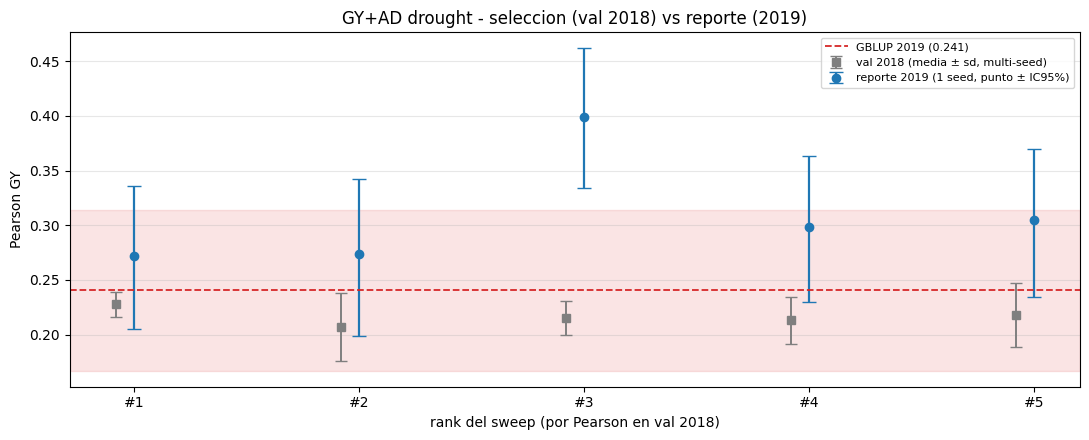

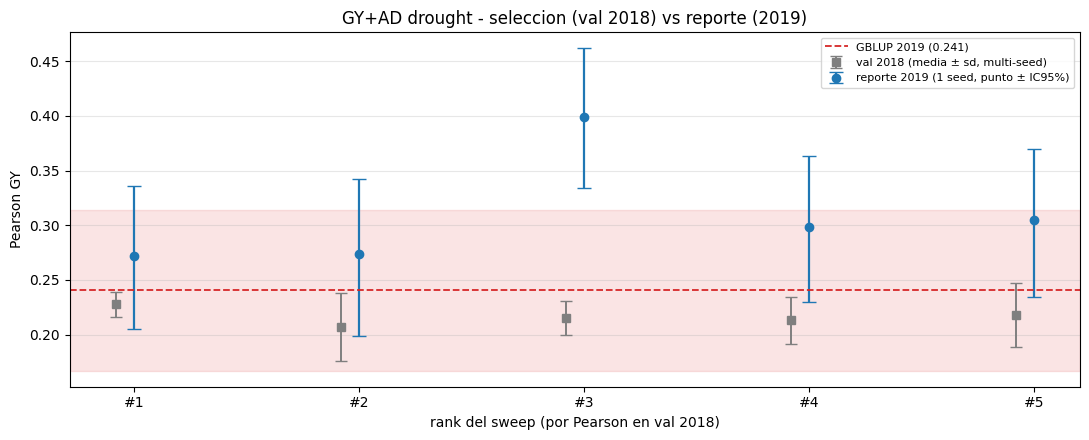

In [6]:
fig = plot_select_vs_report(
    df, baseline=gblup_pt, baseline_label="GBLUP",
    primary_trait=PRIMARY,
    title="GY+AD drought - seleccion (val 2018) vs reporte (2019)",
)
fig

## 4b. El test decisivo: ¿el pico de un trial sobrevive a la seed?

El reporte de arriba usa **una** seed; su IC95% mide remuestreo de *líneas*, no la varianza
de **reentrenar**. Acá reentrenamos cada trial en 2017+2018 con `REPORT_SEEDS` y miramos la
media ± sd en 2019. Si `report_2019` (1 seed) era un pico afortunado, `report_2019_mean`
colapsa hacia el resto y `report_2019_sd` queda grande; si la ventaja fuese real, la media se
sostiene con sd chica.

> Más lento: reentrena `k·len(REPORT_SEEDS)` MLPs en 2017+2018. Lo ya hecho con la seed base
> (575) es *cache hit*; se entrenan solo las seeds nuevas.

In [7]:
df_ms = diagnose_sweep(
    SWEEP_PATH, BASE_CONFIG,
    k=K, seeds=SEEDS, report_seeds=REPORT_SEEDS,
    primary_trait=PRIMARY, n_boot=N_BOOT,
)
cols = ["rank", "run_id", "sel_2018_mean", "report_2019",
        "report_2019_mean", "report_2019_sd", "report_2019_min", "report_2019_max", "loss_weights.AD"]
df_ms[cols]

[diagnose_sweep] oromagnoli-/maze-genomic-pred/92k7ybzc  (multitask, trait primario=GY)
  selección: cv={'train_years': [2017], 'val_year': 2018}  seeds=[575, 576, 577, 578, 579]
  reporte:   cv={'train_years': [2017, 2018], 'val_year': 2019}  n_boot=2000
  top-5 trials traídos del sweep.

  [#1] run c1v857bj  (sweep val2018=0.2379)
        sel2018 = 0.2276 ± 0.0114  |  report2019 = 0.2721  IC95%[0.2051, 0.3364]  |  report2019 multi-seed = 0.2993 ± 0.0289  [0.2660, 0.3328]

  [#2] run pqqetn54  (sweep val2018=0.2377)
        sel2018 = 0.2071 ± 0.0312  |  report2019 = 0.2737  IC95%[0.1988, 0.3421]  |  report2019 multi-seed = 0.2405 ± 0.0585  [0.1807, 0.3225]

  [#3] run pwsunaac  (sweep val2018=0.2376)
        sel2018 = 0.2153 ± 0.0152  |  report2019 = 0.3992  IC95%[0.3345, 0.4617]  |  report2019 multi-seed = 0.3687 ± 0.0237  [0.3387, 0.3992]

  [#4] run 4wwqx817  (sweep val2018=0.2376)
        sel2018 = 0.2130 ± 0.0216  |  report2019 = 0.2986  IC95%[0.2302, 0.3629]  |  report2019 multi

,rank,run_id,sel_2018_mean,report_2019,report_2019_mean,report_2019_sd,report_2019_min,report_2019_max,loss_weights.AD
0,1,c1v857bj,0.227600,0.272070,0.299332,0.028899,0.266024,0.332819,0.350906
1,2,pqqetn54,0.207092,0.273677,0.240532,0.058513,0.180742,0.322548,0.105535
2,3,pwsunaac,0.215280,0.399205,0.368655,0.023707,0.338679,0.399205,0.659498
3,4,4wwqx817,0.213014,0.298554,0.303922,0.017238,0.290188,0.331863,0.320602
4,5,qaj5kwtl,0.217998,0.304545,0.283863,0.029654,0.236888,0.304545,0.138730


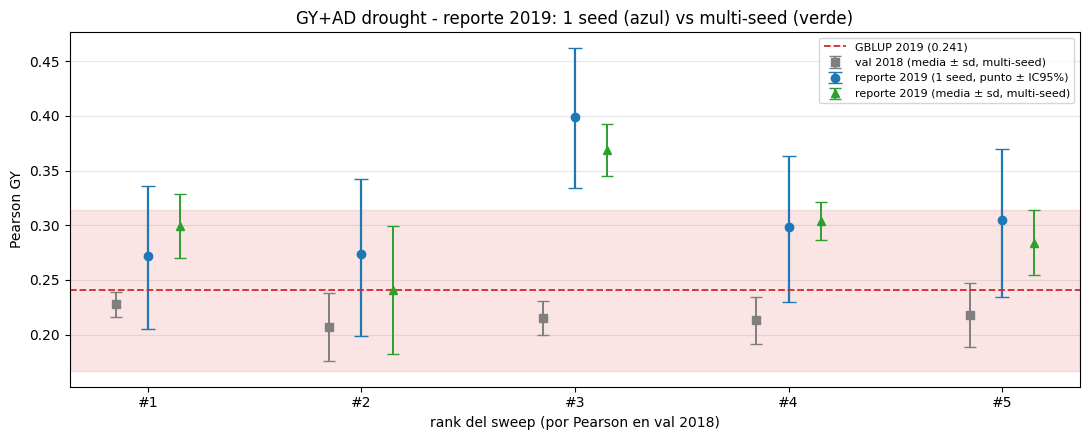

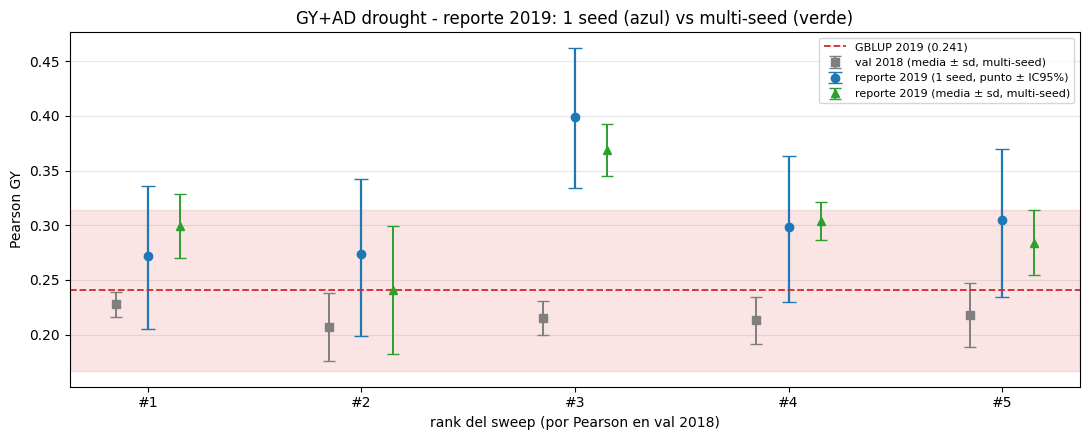

In [8]:
fig2 = plot_select_vs_report(
    df_ms, baseline=gblup_pt, baseline_label="GBLUP",
    primary_trait=PRIMARY,
    title="GY+AD drought - reporte 2019: 1 seed (azul) vs multi-seed (verde)",
)
fig2

## 4c. Barrido controlado de `loss_weights.AD` (¿la región AD-alto ayuda en serio?)

El top-5 sugería "más peso a AD → mejor GY en 2019", pero ahí los HP variaban **todos** a la
vez (AD confundido con `lr`, `dropout`, capacidad...). Acá aislamos el efecto: clavamos todos
los HP en los del **mejor trial** (`..._best1.yaml`, run c1v857bj) y barremos **solo**
`loss_weights.AD`, evaluando en **2018 (selección)** y **2019 (reporte)**, multi-seed.

La pregunta decisiva: ¿la mejora con AD aparece **también en 2018**? Si sí, *es seleccionable
de forma honesta* (podés justificar AD-alto sin mirar 2019). Si solo aparece en 2019, era del
año. (El sweep de wandb equivalente quedó en
`configs/sweep_mlp_multitask_GY_AD_drought_ADonly.yaml`.)

In [9]:
SCAN_BASE   = "configs/exp_mlp_multitask_2017_to_2018_GY_AD_drought_best1.yaml"  # HP del #1
SCAN_VALUES = [0.0, 0.15, 0.35, 0.5, 0.66, 0.85, 1.0]                            # incluye #1 (0.35) y #3 (0.66)

df_ad = scan_hp(
    SCAN_BASE, "model.params.loss_weights.AD", SCAN_VALUES,
    seeds=SEEDS, report_seeds=REPORT_SEEDS, primary_trait=PRIMARY, n_boot=N_BOOT,
)
df_ad

[scan_hp] model.params.loss_weights.AD sobre [0.0, 0.15, 0.35, 0.5, 0.66, 0.85, 1.0]  (trait primario=GY)
  selección: cv={'train_years': [2017], 'val_year': 2018}  seeds=[575, 576, 577, 578, 579]
  reporte:   cv={'train_years': [2017, 2018], 'val_year': 2019}  report_seeds=[575, 576, 577, 578, 579]

  loss_weights.AD=0.0   : sel = 0.2212 ± 0.0080  |  report = 0.2605  IC95%[0.1926, 0.3244]  |  report multi = 0.3142 ± 0.0479
  loss_weights.AD=0.15  : sel = 0.2269 ± 0.0070  |  report = 0.2795  IC95%[0.2137, 0.3421]  |  report multi = 0.3199 ± 0.0254
  loss_weights.AD=0.35  : sel = 0.2253 ± 0.0079  |  report = 0.2614  IC95%[0.1957, 0.3243]  |  report multi = 0.3089 ± 0.0345
  loss_weights.AD=0.5   : sel = 0.2175 ± 0.0104  |  report = 0.2775  IC95%[0.2091, 0.3434]  |  report multi = 0.2878 ± 0.0313
  loss_weights.AD=0.66  : sel = 0.2235 ± 0.0051  |  report = 0.2751  IC95%[0.2080, 0.3400]  |  report multi = 0.3236 ± 0.0317
  loss_weights.AD=0.85  : sel = 0.2178 ± 0.0090  |  report = 0.2870 

,loss_weights.AD,sel_mean,sel_sd,sel_min,sel_max,report_point,report_lo,report_hi,report_mean,report_sd,report_min,report_max
0,0.00,0.221234,0.008015,0.213705,0.230380,0.260467,0.192564,0.324358,0.314232,0.047928,0.260467,0.385791
1,0.15,0.226892,0.006963,0.219960,0.238618,0.279482,0.213677,0.342136,0.319883,0.025399,0.279482,0.342858
2,0.35,0.225271,0.007858,0.217317,0.238334,0.261415,0.195727,0.324277,0.308879,0.034454,0.261415,0.342277
3,0.50,0.217547,0.010433,0.207075,0.229155,0.277491,0.209113,0.343354,0.287803,0.031252,0.237316,0.311603
4,0.66,0.223536,0.005120,0.220459,0.232589,0.275137,0.207989,0.340034,0.323596,0.031682,0.275137,0.358430
5,0.85,0.217794,0.009026,0.203618,0.227414,0.286962,0.220380,0.351611,0.302576,0.030034,0.270954,0.350455
6,1.00,0.223801,0.016158,0.200540,0.239563,0.339294,0.277673,0.400371,0.311907,0.028859,0.284795,0.346858


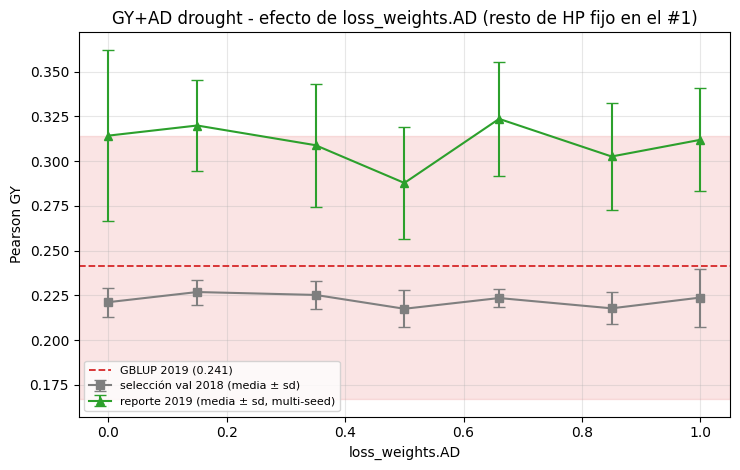

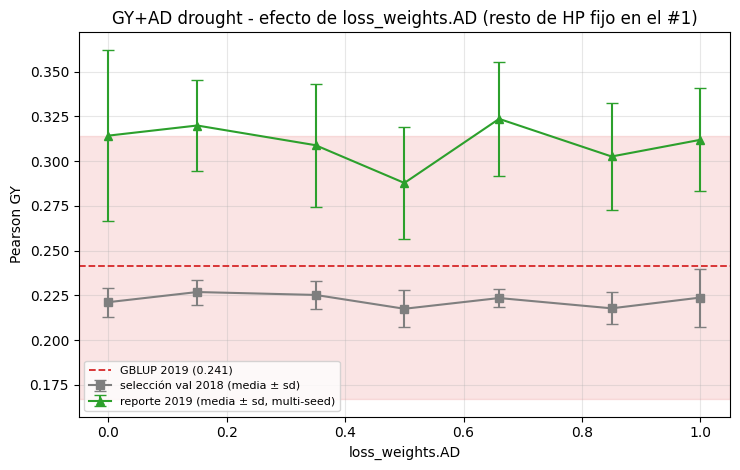

In [10]:
fig3 = plot_hp_scan(
    df_ad, "loss_weights.AD", baseline=gblup_pt, primary_trait=PRIMARY,
    title="GY+AD drought - efecto de loss_weights.AD (resto de HP fijo en el #1)",
)
fig3

## 5. Cómo leer esto (y cómo elegir de forma defendible)

**Mirá tres cosas, en este orden:**

1. **¿`sel_2018_mean` reordena el ranking del sweep?** El sweep ordenó por `sweep_2018_1seed`
   (1 sola seed). Si al promediar seeds el "mejor" cambia de lugar, entonces *"siempre el #3"*
   era **ruido de seed**, no una propiedad del trial. El índice 3 no significa nada.

2. **¿Se solapan los IC95% de `report_2019` entre ranks?** Si sí (lo más probable con este
   `n`), los top están **empatados** en 2019: no hay base estadística para decir "el #3 es
   mejor". Quedarte con el de mayor punto es post-selección (techo optimista).

3. **¿Qué comparten los HP de los de mayor `sel_2018_mean`?** (dropout, `weight_decay`,
   `hidden_dims`, `loss_weights.AD`). Esa **región de HP** es lo que conviene fijar para la
   búsqueda final. Para el arm multitask: si los mejores tienen `loss_weights.AD ≈ 0`, la
   tarea auxiliar **no** está ayudando (es un single-task regularizado); si AD se asienta en
   un rango claro, ahí está la evidencia de que el multitask aporta.

**Receta honesta de elección (lo que va al informe):** fijá el trial por su comportamiento en
**2018** (mayor `sel_2018_mean`; desempate por el más simple / más regularizado dentro de los
IC que se solapan). Reportá *ese* número en 2019. Usá el top-`k` en 2019 como banda de
sensibilidad ("los `k` mejores le ganan a GBLUP"), **no** como excusa para elegir el #3.
El árbitro final es **2020, sellado** — no lo toques hasta el cierre.

---

### Reusar para *optimal* (u otro sweep)

Cambiá el bloque de parámetros de la sección 1 por los del otro experimento, por ejemplo:

```python
SWEEP_PATH   = "oromagnoli-/maze-genomic-pred/<sweep_id_optimal>"
BASE_CONFIG  = "configs/exp_mlp_multitask_2017_to_2018_GY_AD.yaml"        # env: optimal
GBLUP_CONFIG = "configs/exp_gblup_2017_2018_to_2019.yaml"                 # baseline optimal 2019
```

y volvé a correr las celdas. Para la **red sola** (single-task) apuntá `BASE_CONFIG` a su
`exp_mlp_...` y `SWEEP_PATH` a su sweep: `diagnose_sweep` detecta el tipo desde `model.name` y
rutea solo (la métrica primaria pasa a ser `pearson_r` del único target). Si el `cv` base no
fuera val 2018 → 2019, pasá `report_cv={...}` explícito a `diagnose_sweep`.

## 6. ¿Le gana a GBLUP? Significancia con delta pareado — 

Trae el **trial #1** del sweep en el reporte 2019 con la **seed base** y como
**ensemble de seeds** (promedio de predicciones — menor varianza, y la forma honesta de
"cobrar" el ~0.30 multi-seed), más el **GBLUP**, todo alineado por línea, y calcula el **delta
pareado** (bootstrap cluster por línea): el test correcto para "¿le gana?", que compara el
MISMO resample en vez de IC sueltos. Si el IC95% del delta no cruza 0 (marcado con `*`), la
diferencia es significativa.

Para otro caso (optimal, otro trial), cambiá `sweep_path` / `base_config` / `baseline_config`
/ `rank` dentro de la celda.

[compare] trial #1 de oromagnoli-/maze-genomic-pred/92k7ybzc vs GBLUP  (reporte val_year=2019, seeds=[575, 576, 577, 578, 579])

Delta pareado vs GBLUP (bootstrap cluster por línea, n=721 líneas; * = IC95% no cruza 0):

[pearson_r]
    GBLUP                              +0.2413
    MLP MT GY+AD (seed 575)            +0.2721   Δ=+0.0307  IC95%[-0.0072, +0.0661]
    MLP MT GY+AD (ensemble 5)          +0.3091   Δ=+0.0676  IC95%[+0.0370, +0.0982]  *

[matching20]
    GBLUP                              +0.3542
    MLP MT GY+AD (seed 575)            +0.3611   Δ=+0.0029  IC95%[-0.0417, +0.0486]
    MLP MT GY+AD (ensemble 5)          +0.3819   Δ=+0.0300  IC95%[-0.0208, +0.0833]



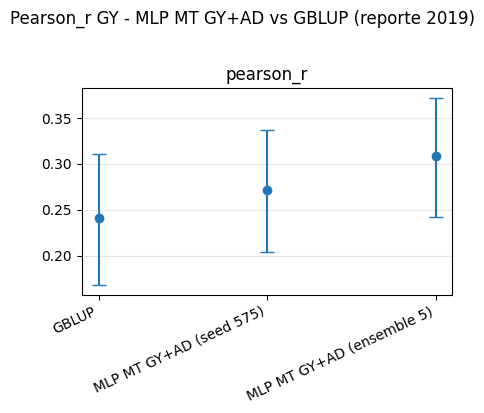

In [11]:

import os, sys
from pathlib import Path

_root = Path.cwd()
while _root != _root.parent and not (_root / "src").is_dir():
    _root = _root.parent
os.chdir(_root)
if str(_root) not in sys.path:
    sys.path.insert(0, str(_root))

from src.eval.sweep_diagnostics import compare_trial_vs_baseline

res_sig = compare_trial_vs_baseline(
    sweep_path="oromagnoli-/maze-genomic-pred/92k7ybzc",
    base_config="configs/exp_mlp_multitask_2017_to_2018_GY_AD_drought.yaml",
    baseline_config="configs/exp_gblup_2017_2018_to_2019_drought.yaml",
    rank=1, seeds=(575, 576, 577, 578, 579),
    model_label="MLP MT GY+AD Drought", baseline_label="GBLUP",
    primary_trait="GY", n_boot=2000,
)

[compare] trial #1 de oromagnoli-/maze-genomic-pred/92k7ybzc vs GBLUP  (reporte val_year=2019, seeds=[575, 576, 577, 578, 579, 580, 581, 582, 583, 584, 585])

Delta pareado vs GBLUP (bootstrap cluster por línea, n=721 líneas; * = IC95% no cruza 0):

[pearson_r]
    GBLUP                              +0.2413
    MLP MT GY+AD Drought (seed 575)    +0.2721   Δ=+0.0307  IC95%[-0.0072, +0.0661]
    MLP MT GY+AD Drought (ensemble 11) +0.3229   Δ=+0.0814  IC95%[+0.0517, +0.1125]  *

[matching20]
    GBLUP                              +0.3542
    MLP MT GY+AD Drought (seed 575)    +0.3611   Δ=+0.0029  IC95%[-0.0417, +0.0486]
    MLP MT GY+AD Drought (ensemble 11) +0.3958   Δ=+0.0494  IC95%[+0.0000, +0.1042]



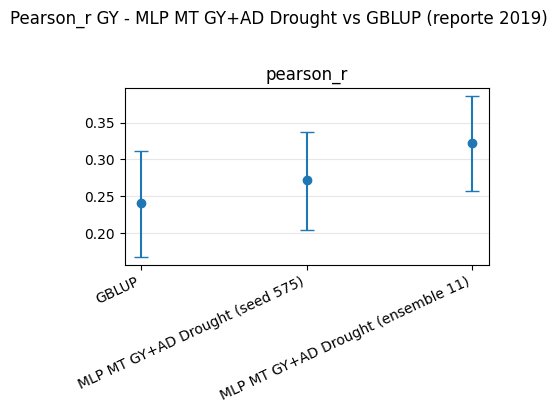

In [17]:
import os, sys
from pathlib import Path

_root = Path.cwd()
while _root != _root.parent and not (_root / "src").is_dir():
    _root = _root.parent
os.chdir(_root)
if str(_root) not in sys.path:
    sys.path.insert(0, str(_root))

from src.eval.sweep_diagnostics import compare_trial_vs_baseline

res_sig = compare_trial_vs_baseline(
    sweep_path="oromagnoli-/maze-genomic-pred/92k7ybzc",
    base_config="configs/exp_mlp_multitask_2017_to_2018_GY_AD_drought.yaml",
    baseline_config="configs/exp_gblup_2017_2018_to_2019_drought.yaml",
    rank=1, seeds=(575, 576, 577, 578, 579, 580, 581, 582, 583, 584, 585),
    model_label="MLP MT GY+AD Drought", baseline_label="GBLUP",
    primary_trait="GY", n_boot=2000,
)

[compare] trial #1 de oromagnoli-/maze-genomic-pred/tt24pyzx vs GBLUP  (reporte val_year=2019, seeds=[575, 576, 577, 578, 579])

Delta pareado vs GBLUP (bootstrap cluster por línea, n=721 líneas; * = IC95% no cruza 0):

[pearson_r]
    GBLUP                              +0.2413
    MLP drought (seed 575)             +0.2619   Δ=+0.0204  IC95%[-0.0309, +0.0706]
    MLP drought (ensemble 5)           +0.2368   Δ=-0.0045  IC95%[-0.0398, +0.0301]

[matching20]
    GBLUP                              +0.3542
    MLP drought (seed 575)             +0.3333   Δ=-0.0096  IC95%[-0.0833, +0.0625]
    MLP drought (ensemble 5)           +0.3194   Δ=-0.0215  IC95%[-0.0694, +0.0347]



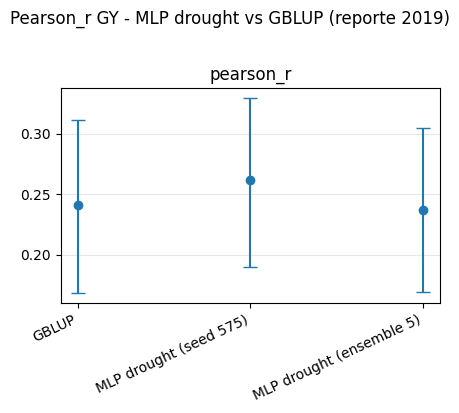

In [18]:

import os, sys
from pathlib import Path

_root = Path.cwd()
while _root != _root.parent and not (_root / "src").is_dir():
    _root = _root.parent
os.chdir(_root)
if str(_root) not in sys.path:
    sys.path.insert(0, str(_root))

from src.eval.sweep_diagnostics import compare_trial_vs_baseline

res_sig = compare_trial_vs_baseline(
    sweep_path="oromagnoli-/maze-genomic-pred/tt24pyzx",
    base_config="configs/exp_mlp_2017_to_2018_drought.yaml",
    baseline_config="configs/exp_gblup_2017_2018_to_2019_drought.yaml",
    rank=1, seeds=(575, 576, 577, 578, 579),
    model_label="MLP drought", baseline_label="GBLUP",
    primary_trait="GY", n_boot=2000,
)

[compare] trial #1 de oromagnoli-/maze-genomic-pred/yj2h9x3g vs GBLUP  (reporte val_year=2019, seeds=[575, 576, 577, 578, 579])

Delta pareado vs GBLUP (bootstrap cluster por línea, n=722 líneas; * = IC95% no cruza 0):

[pearson_r]
    GBLUP                              +0.3145
    MLP MT GY+PH+AD (seed 575)         +0.3368   Δ=+0.0218  IC95%[-0.0129, +0.0560]
    MLP MT GY+PH+AD (ensemble 5)       +0.3080   Δ=-0.0068  IC95%[-0.0350, +0.0209]

[matching20]
    GBLUP                              +0.3958
    MLP MT GY+PH+AD (seed 575)         +0.4375   Δ=+0.0485  IC95%[-0.0208, +0.1181]
    MLP MT GY+PH+AD (ensemble 5)       +0.4236   Δ=+0.0177  IC95%[-0.0417, +0.0764]



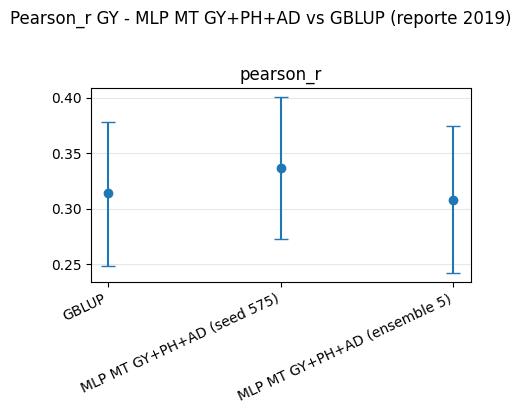

In [19]:
import os, sys
from pathlib import Path

_root = Path.cwd()
while _root != _root.parent and not (_root / "src").is_dir():
    _root = _root.parent
os.chdir(_root)
if str(_root) not in sys.path:
    sys.path.insert(0, str(_root))

from src.eval.sweep_diagnostics import compare_trial_vs_baseline

res_sig = compare_trial_vs_baseline(
    sweep_path="oromagnoli-/maze-genomic-pred/yj2h9x3g",
    base_config="configs/exp_mlp_multitask_2017_to_2018.yaml",
    baseline_config="configs/exp_gblup_2017_2018_to_2019.yaml",
    rank=1, seeds=(575, 576, 577, 578, 579),
    model_label="MLP MT GY+PH+AD", baseline_label="GBLUP",
    primary_trait="GY", n_boot=2000,
)